# LM7 Lab — Multivariable Calculus and Lagrange Multipliers

Companion notebook to **From Calculus to Kelly, LM7**. It rebuilds the module's exhibits and computational examples from verified price files, solves the computational practice problems, and ends with an extension exercise.

| Part | Rebuilds |
|:--|:--|
| 1 | Total-return series for 0050 and 00679B: verification, dividends, split, common dates |
| 2 | The case (Exhibit 1), statistics by year (Exhibit 6), correlation at three frequencies, rolling correlation (Exhibit 7) |
| 3 | Partial derivatives: 00679B in 2022 (Example 1), marginal variance (Example 2), Taylor attribution (Exhibit 2) |
| 4 | The growth function: gradient and Hessian at zero, exact vs quadratic model (Exhibit 3) |
| 5 | Unconstrained optimization: least squares (Example 3), classifying critical points (Example 4) |
| 6 | Lagrange multipliers solved symbolically and numerically (Examples 5–6, Exhibit 5) |
| 7 | Two-asset portfolios: minimum variance in and out of sample, tangency and Kelly (Examples 7–8, Exhibits 8–10) |
| 8 | KKT: equity floor and leverage cap (Examples 9–10, Exhibit 11) |
| 9 | Numerical gradients, Newton vs gradient ascent (Exhibit 12) |
| 10 | Practice-problem solutions and an extension exercise |

**Data.** `data/` holds a snapshot of FinMind `TaiwanStockPrice` closes (with FinMind's `spread` column) for 0050 and 00679B, and the cash dividends from `TaiwanStockDividendResult`, retrieved 2026-10-10. Prices are unadjusted; Part 1 handles dividends and the 0050 split explicitly. The folder is not in the repository (FinMind's licence forbids redistributing raw data): build it from the repository root with `python3 data/fetch_finmind.py` and `python3 data/make_lab_data.py` (needs `FINMIND_TOKEN`).

**Environment.** `uv pip install polars pyarrow numpy scipy sympy matplotlib`.

**Conventions (as in the module).** Daily simple total returns between consecutive common trading dates from the base date 2017-01-17; moments with divisor $T$; annualization with $A=T/\text{years}\approx243.05$; an illustrative $r_f=1.5\%$ for tangency and Kelly.

In [1]:
from pathlib import Path
from datetime import date
import math
import numpy as np
import polars as pl
import matplotlib.pyplot as plt

DATA = Path("data")
BASE, RF = "2017-01-17", 0.015
pl.Config.set_tbl_rows(40)
pl.Config.set_float_precision(6)
plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

## Part 1 — Total-return series

* Every close must satisfy `close[t] − close[t−1] = spread[t]`. FinMind prints `spread = 0` on ex-dividend days and uses the split-adjusted reference on 0050's split day (4-for-1, **2025-06-18**), so those are the only mismatches allowed.
* 00679B has **37** ex-dates in the window. On two of them (2019-03-05 and 2025-08-21) the close did not change, so they produce no mismatch — but their dividends must still be paid. We therefore apply dividends from the dividend file on every ex-date and check that the previous close equals FinMind's `before_price`.
* Each fund's total-return index is built on its own calendar; returns are taken between consecutive **common** dates (0050 was halted 2025-06-11..17 while 00679B traded).

In [2]:
SPLITS = {"0050": ("2025-06-18", 4.0)}

def load(sym):
    raw = pl.read_csv(DATA / f"{sym}_daily_raw.csv").sort("date")
    div = pl.read_csv(DATA / f"{sym}_dividends.csv").filter(pl.col("date") > raw["date"][0])
    chk = (raw.with_columns((pl.col("close") - pl.col("close").shift(1) - pl.col("spread")).abs().alias("gap"))
              .filter(pl.col("gap") > 0.005))
    sdate = SPLITS.get(sym, (None, 1.0))[0]
    allowed = set(div["date"]) | ({sdate} if sdate else set())
    unexplained = sorted(set(chk["date"]) - allowed)
    silent = sorted(set(div["date"]) - set(chk["date"]))
    prev = raw.with_columns(pl.col("close").shift(1).alias("prev")).join(div, on="date", how="inner")
    assert prev.height == div.height, "an ex-date is not a trading date"
    assert (prev["prev"] - prev["before_price"]).abs().max() < 1e-9, "previous close != before_price"
    print(f"{sym}: {raw.height} rows {raw['date'][0]} -> {raw['date'][-1]}; ex-dates {div.height}; "
          f"mismatches {chk.height}; unexplained {unexplained}; ex-dates without mismatch {silent}")
    assert not unexplained
    return raw, div

def tr_index(sym):
    raw, div = load(sym)
    sdate, k = SPLITS.get(sym, ("", 1.0))
    return (raw.join(div.select("date", pl.col("cash_dividend").alias("D")), on="date", how="left")
               .with_columns(pl.col("D").fill_null(0.0),
                             pl.when(pl.col("date") == pl.lit(sdate)).then(pl.lit(k)).otherwise(pl.lit(1.0)).alias("k"))
               .with_columns(((pl.col("close") + pl.col("D")) / (pl.col("close").shift(1) / pl.col("k"))).fill_null(1.0).alias("G"))
               .select("date", pl.col("G").cum_prod().alias(f"I_{sym}")))

idx = (tr_index("0050").join(tr_index("00679B"), on="date", how="inner")
          .filter(pl.col("date") >= pl.lit(BASE)).sort("date")
          .with_columns(pl.col("I_0050") / pl.col("I_0050").first(), pl.col("I_00679B") / pl.col("I_00679B").first()))
ret = (idx.with_columns((pl.col("I_0050") / pl.col("I_0050").shift(1) - 1).alias("R1"),
                        (pl.col("I_00679B") / pl.col("I_00679B").shift(1) - 1).alias("R2"))
          .drop_nulls("R1").with_columns(pl.col("date").str.to_date()))
R1, R2 = ret["R1"].to_numpy(), ret["R2"].to_numpy()
T = len(R1)
years = (ret["date"][-1] - date.fromisoformat(BASE)).days / 365.25
A = T / years
yr = ret["date"].dt.year().to_numpy()
IS, OOS, ALL = yr <= 2021, yr >= 2022, np.ones(T, bool)
print(f"T = {T} returns, {ret['date'][0]} -> {ret['date'][-1]}, years = {years:.4f}, A = {A:.2f}")
print(f"growth: 0050 x{np.prod(1 + R1):.4f}, 00679B x{np.prod(1 + R2):.4f}")
assert T == 2363

0050: 2907 rows 2014-10-31 -> 2026-10-08; ex-dates 22; mismatches 23; unexplained []; ex-dates without mismatch []
00679B: 2369 rows 2017-01-17 -> 2026-10-08; ex-dates 37; mismatches 35; unexplained []; ex-dates without mismatch ['2019-03-05', '2025-08-21']
T = 2363 returns, 2017-01-18 -> 2026-10-08, years = 9.7221, A = 243.05
growth: 0050 x8.6733, 00679B x0.8267


## Part 2 — The case, statistics by year, and correlation at three frequencies

`est(mask)` returns annualized population moments and every two-asset quantity used in the module: the minimum-variance weight (7.7) and volatility (7.8), the multiplier $\lambda^*=2\sigma_{\min}^2$, the Kelly fractions (7.12), the tangency weights (7.10) and $SR^*$ (7.11).

In [3]:
def est(m, rf=RF):
    a, b = R1[m], R2[m]
    S = np.cov(np.vstack([a, b]), ddof=0) * A
    s1, s2, c = math.sqrt(S[0, 0]), math.sqrt(S[1, 1]), S[0, 1]
    D = S[0, 0] + S[1, 1] - 2 * c
    w = (S[1, 1] - c) / D
    vmin = (S[0, 0] * S[1, 1] - c * c) / D
    e = np.array([A * a.mean() - rf, A * b.mean() - rf])
    f = np.linalg.solve(S, e)                                    # Kelly fractions, eq. (7.12)
    sr = e / np.array([s1, s2]); rho = c / (s1 * s2)
    return dict(n=int(m.sum()), s1=s1, s2=s2, cov=c, rho=rho, w_mv=w, s_mv=math.sqrt(vmin), lam=2 * vmin, D=D,
                e1=e[0], e2=e[1], f1=f[0], f2=f[1], lev=f.sum(), wT1=f[0] / f.sum(),
                sr_star=math.sqrt((sr[0]**2 + sr[1]**2 - 2 * rho * sr[0] * sr[1]) / (1 - rho**2)),
                ret1=np.prod(1 + a) - 1, ret2=np.prod(1 + b) - 1, S=S)

E = {"full": est(ALL), "2017–2021": est(IS), "2022–2026": est(OOS)}
w_is = E["2017–2021"]["w_mv"]
vol = lambda x: math.sqrt(A * x.var())
mix = lambda w, m: w * R1[m] + (1 - w) * R2[m]
case = pl.DataFrame([{"window": k, "days": v["n"], "0050 return": v["ret1"], "00679B return": v["ret2"], "sigma_0050": v["s1"],
                      "sigma_00679B": v["s2"], "rho": v["rho"], "w_min_var": v["w_mv"], "sigma_min": v["s_mv"],
                      "vol of 42.3/57.7 mix": vol(mix(w_is, m))} for (k, v), m in zip(E.items(), (ALL, IS, OOS))])
case   # Exhibit 1

window,days,0050 return,00679B return,sigma_0050,sigma_00679B,rho,w_min_var,sigma_min,vol of 42.3/57.7 mix
str,i64,f64,f64,f64,f64,f64,f64,f64,f64
"""full""",2363,7.673295,-0.173251,0.201060,0.134959,-0.105632,0.327476,0.106352,0.109088
"""2017–2021""",1213,1.380383,0.156072,0.163706,0.135475,-0.221314,0.423174,0.092248,0.092248
"""2022–2026""",1150,2.643655,-0.284864,0.234031,0.134335,-0.021900,0.252507,0.115392,0.124404


In [4]:
years_tbl = pl.DataFrame([{"year": y, "days": int((yr == y).sum()), "0050": est(yr == y)["ret1"], "00679B": est(yr == y)["ret2"],
                           "sigma_0050": est(yr == y)["s1"], "sigma_00679B": est(yr == y)["s2"], "rho": est(yr == y)["rho"],
                           "w_min_var": est(yr == y)["w_mv"]} for y in range(2017, 2027)])
years_tbl   # Exhibit 6 (2026 runs to 8 October)

year,days,0050,00679B,sigma_0050,sigma_00679B,rho,w_min_var
i64,i64,f64,f64,f64,f64,f64,f64
2017,235,0.173168,-0.002177,0.092614,0.083862,-0.036140,0.452246
2018,247,-0.049511,0.006901,0.163077,0.089979,-0.394151,0.300055
2019,242,0.335157,0.137072,0.121920,0.122277,-0.433889,0.501018
2020,245,0.310844,0.081298,0.227989,0.213104,-0.166282,0.471090
2021,244,0.219709,-0.064139,0.175505,0.125462,-0.174298,0.361104
2022,246,-0.213416,-0.220919,0.216474,0.160785,-0.063255,0.363781
2023,239,0.273978,0.031084,0.139424,0.126117,0.198984,0.437672
2024,242,0.486715,-0.029009,0.246261,0.110316,-0.241219,0.217908
2025,238,0.368534,-0.006222,0.245468,0.157322,0.009924,0.289263


 1w: n=502  2017-2021 -0.15   2022-2026 +0.09
1mo: n=118  2017-2021 -0.29   2022-2026 +0.21
lead-lag: corr(R1_t, R2_t-1) = +0.023, corr(R1_t-1, R2_t) = -0.021


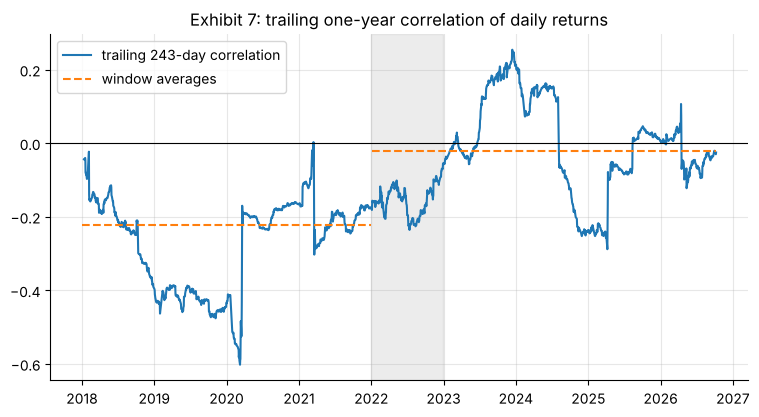

In [5]:
# correlation at weekly and monthly frequency, and lead-lag at daily frequency
lev = idx.with_columns(pl.col("date").str.to_date())
for every in ("1w", "1mo"):
    w = lev.group_by_dynamic("date", every=every).agg(pl.col("I_0050").last(), pl.col("I_00679B").last()).sort("date")
    a = np.concatenate([[1.0], w["I_0050"].to_numpy()]); b = np.concatenate([[1.0], w["I_00679B"].to_numpy()])
    r1, r2 = a[1:] / a[:-1] - 1, b[1:] / b[:-1] - 1
    yy = w["date"].dt.year().to_numpy()
    print(f"{every:>3}: n={len(r1)}  2017-2021 {np.corrcoef(r1[yy <= 2021], r2[yy <= 2021])[0, 1]:+.2f}   2022-2026 {np.corrcoef(r1[yy >= 2022], r2[yy >= 2022])[0, 1]:+.2f}")
print(f"lead-lag: corr(R1_t, R2_t-1) = {np.corrcoef(R1[1:], R2[:-1])[0, 1]:+.3f}, corr(R1_t-1, R2_t) = {np.corrcoef(R1[:-1], R2[1:])[0, 1]:+.3f}")

roll = ret.select("date", pl.rolling_corr(pl.col("R1"), pl.col("R2"), window_size=243).alias("rho_243")).drop_nulls()
fig, ax = plt.subplots()
ax.plot(roll["date"], roll["rho_243"], label="trailing 243-day correlation")
ax.axvspan(date(2022, 1, 1), date(2022, 12, 31), color="grey", alpha=0.15)
ax.hlines([E["2017–2021"]["rho"], E["2022–2026"]["rho"]], [date(2018, 1, 1), date(2022, 1, 3)], [date(2021, 12, 30), date(2026, 10, 8)],
          colors="tab:orange", linestyles="dashed", label="window averages")
ax.axhline(0, color="black", lw=0.8); ax.set_title("Exhibit 7: trailing one-year correlation of daily returns"); ax.legend(); plt.show()

## Part 3 — Partial derivatives and a Taylor attribution

**Example 1.** $f(x,y)=(1+x)(1+y)-1$ with USD/TWD from 27.690 to 30.708 in 2022 (central-bank close via CNA).
**Example 2.** Partial derivatives of $V(w_1,w_2)$ at 60/40 with full-sample moments.
**Exhibit 2.** First- and second-order Taylor terms of $V(\sigma_1,\sigma_2,\rho)=w_1^2\sigma_1^2+w_2^2\sigma_2^2+2w_1w_2\rho\sigma_1\sigma_2$ at fixed weights.

In [6]:
r22 = est(yr == 2022)["ret2"]; y = 30.708 / 27.690 - 1; x = (1 + r22) / (1 + y) - 1
print(f"Example 1: R_TWD {r22:.2%}, FX {y:.2%}, implied USD return {x:.2%}; f_x = {1 + y:.4f}, f_y = {1 + x:.4f}; "
      f"x + y = {x + y:.2%}, cross term {x * y:.2%}")

F = E["full"]; S = F["S"]; w = np.array([0.6, 0.4])
V = w @ S @ w; grad = 2 * S @ w
print(f"Example 2: V = {V:.6f}, sigma = {math.sqrt(V):.2%}, dV/dw = {grad.round(4)}, dsigma/dw = {(grad / (2 * math.sqrt(V))).round(3)}")
for h in (np.array([0.01, 0.0]), np.array([0.01, -0.01])):
    print(f"   step {h}: linear {grad @ h / (2 * math.sqrt(V)) * 100:.3f} pp, exact {(math.sqrt((w + h) @ S @ (w + h)) - math.sqrt(V)) * 100:.3f} pp")

Example 1: R_TWD -22.09%, FX 10.90%, implied USD return -29.75%; f_x = 1.1090, f_y = 0.7025; x + y = -18.85%, cross term -3.24%
Example 2: V = 0.016092, sigma = 12.69%, dV/dw = [0.0462 0.0111], dsigma/dw = [0.182 0.044]
   step [0.01 0.  ]: linear 0.182 pp, exact 0.182 pp
   step [ 0.01 -0.01]: linear 0.138 pp, exact 0.140 pp


In [7]:
e0, e1 = E["2017–2021"], E["2022–2026"]
a, b, c = w_is**2, (1 - w_is)**2, 2 * w_is * (1 - w_is)
Vf = lambda s1, s2, r: a * s1**2 + b * s2**2 + c * r * s1 * s2
p0 = np.array([e0["s1"], e0["s2"], e0["rho"]]); d = np.array([e1["s1"], e1["s2"], e1["rho"]]) - p0
s1, s2, r = p0
grad = np.array([2 * a * s1 + c * r * s2, 2 * b * s2 + c * r * s1, c * s1 * s2])
H = np.array([[2 * a, c * r, c * s2], [c * r, 2 * b, c * s1], [c * s2, c * s1, 0.0]])
first = grad * d
exact = Vf(*(p0 + d)) - Vf(*p0)
print("partial derivatives:", grad.round(4))
print("first-order terms (%^2):", (first * 1e4).round(2), " total", round(first.sum() * 1e4, 2))
print("second-order approximation (%^2):", round((first.sum() + 0.5 * d @ H @ d) * 1e4, 2), " exact:", round(exact * 1e4, 2))
print("third-order term (%^2):", round(c * d[0] * d[1] * d[2] * 1e4, 3), "  volatility", f"{math.sqrt(Vf(*p0)):.2%} -> {math.sqrt(Vf(*(p0 + d))):.2%}")

partial derivatives: [0.044  0.0725 0.0108]
first-order terms (%^2): [30.94 -0.83 21.59]  total 51.7
second-order approximation (%^2): 69.74  exact: 69.67
third-order term (%^2): -0.078   volatility 9.22% -> 12.44%


## Part 4 — The growth function and its quadratic model (Exhibit 3)

$g(f_1,f_2)=A\cdot\frac1T\sum_t\ln(1+r+f_1X_{1t}+f_2X_{2t})$ with $X_i=R_i-r$, $r=r_f/A$; the model (7.3) is $r_f+f_1e_1+f_2e_2-\tfrac12(f_1^2\sigma_1^2+2f_1f_2\sigma_{12}+f_2^2\sigma_2^2)$.

In [8]:
r = RF / A
X = np.column_stack([R1, R2]) - r

def g(f, m=ALL):
    return A * np.log1p(r + X[m] @ np.asarray(f, float)).mean()

def g_model(f, e=F):
    f = np.asarray(f, float)
    return RF + f @ np.array([e["e1"], e["e2"]]) - 0.5 * f @ e["S"] @ f

def grad_hess(f, m=ALL):
    Xm = X[m]; wgt = 1 / (1 + r + Xm @ np.asarray(f, float))
    return A * (Xm * wgt[:, None]).mean(0), -A * (Xm.T * wgt**2) @ Xm / len(Xm)

g0, H0 = grad_hess(np.zeros(2))
print("gradient at 0:", g0.round(4), " e =", np.round([F["e1"], F["e2"]], 4))
print("Hessian at 0:", H0.round(4).tolist(), " -Sigma =", (-F["S"]).round(4).tolist())
fstar = np.array([F["f1"], F["f2"]])
pts = {"0050 alone": (1, 0), "00679B alone": (0, 1), "min-var mix": (F["w_mv"], 1 - F["w_mv"]), "2 x 0050": (2, 0),
       "half Kelly": tuple(0.5 * fstar), "full Kelly (model)": tuple(fstar)}
pl.DataFrame([{"portfolio": k, "f1": v[0], "f2": v[1], "exact g": g(v), "model g": g_model(v), "error bp": (g_model(v) - g(v)) * 1e4}
              for k, v in pts.items()])   # Exhibit 3

gradient at 0: [ 0.2275 -0.0255]  e = [ 0.2275 -0.0255]
Hessian at 0: [[-0.0406, 0.0029], [0.0029, -0.0182]]  -Sigma = [[-0.0404, 0.0029], [0.0029, -0.0182]]


portfolio,f1,f2,exact g,model g,error bp
str,f64,f64,f64,f64,f64
"""0050 alone""",1.000000,0.000000,0.222200,0.222297,0.972321
"""00679B alone""",0.000000,1.000000,-0.019569,-0.019573,-0.038254
"""min-var mix""",0.327476,0.672524,0.066705,0.066722,0.169625
"""2 x 0050""",2.000000,0.000000,0.388741,0.389168,4.276491
"""half Kelly""",2.795575,-0.259146,0.495495,0.496964,14.691301
"""full Kelly (model)""",5.591150,-0.518292,0.637424,0.657619,201.954559


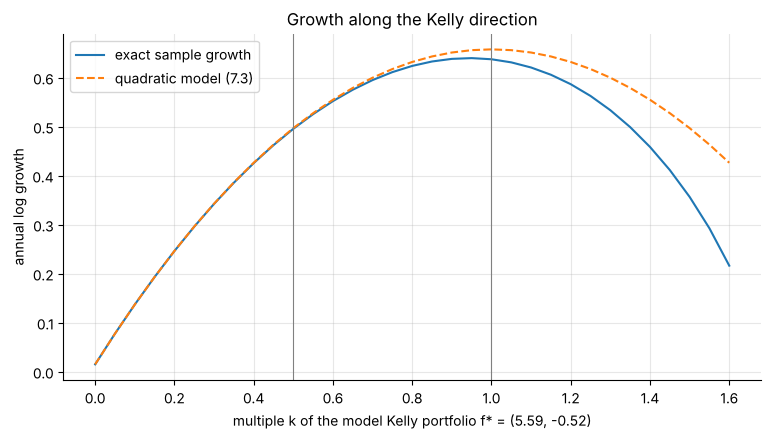

worst day at f*: -56.87% on 2025-04-07


In [9]:
ks = np.linspace(0, 1.6, 33)
fig, ax = plt.subplots()
ax.plot(ks, [g(k * fstar) for k in ks], label="exact sample growth")
ax.plot(ks, [g_model(k * fstar) for k in ks], "--", label="quadratic model (7.3)")
ax.axvline(0.5, color="grey", lw=0.8); ax.axvline(1.0, color="grey", lw=0.8)
ax.set_xlabel("multiple k of the model Kelly portfolio f* = (5.59, -0.52)"); ax.set_ylabel("annual log growth")
ax.set_title("Growth along the Kelly direction"); ax.legend(); plt.show()
worst = (r + X @ fstar).min()
print(f"worst day at f*: {worst:.2%} on {ret['date'][int(np.argmin(r + X @ fstar))]}")

## Part 5 — Unconstrained optimization

**Example 3** fits $y_t=\alpha+\beta x_t$ (00679B on 0050) by solving the normal equations; **Example 4** classifies the critical points of $x^3-3xy+y^3$ with SymPy.

In [10]:
xv, yv = R1, R2
M = np.array([[T, xv.sum()], [xv.sum(), (xv**2).sum()]])
alpha, beta = np.linalg.solve(M, [yv.sum(), (xv * yv).sum()])     # normal equations
Hs = 2 * M
print(f"beta = {beta:.4f}, alpha = {alpha:.4%} a day ({alpha * A:.2%} a year); rho*s2/s1 = {F['rho'] * F['s2'] / F['s1']:.4f}")
print(f"Hessian 2*[[T, sum x], [sum x, sum x^2]]: S_aa = {Hs[0, 0]:.0f}, S_ab = {Hs[0, 1]:.3f}, S_bb = {Hs[1, 1]:.4f}, D = {np.linalg.det(Hs):.1f}")
print(f"R^2 = {np.corrcoef(xv, yv)[0, 1]**2:.2%}")

beta = -0.0709, alpha = 0.0028% a day (0.67% a year); rho*s2/s1 = -0.0709
Hessian 2*[[T, sum x], [sum x, sum x^2]]: S_aa = 4726, S_ab = 4.715, S_bb = 0.7907, D = 3714.8
R^2 = 1.12%


In [11]:
import sympy as sp
xs, ys = sp.symbols("x y", real=True)
f = xs**3 - 3 * xs * ys + ys**3
crit = sp.solve([sp.diff(f, xs), sp.diff(f, ys)], [xs, ys], dict=True)
Hf = sp.hessian(f, (xs, ys))
for cp in crit:
    if all(v.is_real for v in cp.values()):
        Hc = Hf.subs(cp); D = Hc.det()
        kind = "saddle" if D < 0 else ("local min" if Hc[0, 0] > 0 else "local max") if D > 0 else "inconclusive"
        print(cp, " f =", f.subs(cp), " D =", D, " ->", kind)

{x: 0, y: 0}  f = 0  D = -9  -> saddle
{x: 1, y: 1}  f = -1  D = 27  -> local min


## Part 6 — Lagrange multipliers, symbolically and numerically

**Example 5** (order split, illustrative $k_d=2$, $k_n=5$) and **Example 6** (risk budget across two strategies, illustrative figures). Each multiplier is checked against the shadow-price identity (7.6) by re-solving with the constraint relaxed.

In [12]:
from scipy.optimize import minimize
xq, yq, lam, Q = sp.symbols("x y lambda Q", positive=True)
Lg = 2 * xq**2 + 5 * yq**2 - lam * (xq + yq - Q)
sol = sp.solve([sp.diff(Lg, v) for v in (xq, yq, lam)], [xq, yq, lam], dict=True)[0]
print("split:", {k: sp.simplify(v) for k, v in sol.items()}, " at Q=100:", {k: float(v.subs(Q, 100)) for k, v in sol.items()})
Cstar = sp.simplify((2 * xq**2 + 5 * yq**2).subs(sol))
print("C*(Q) =", Cstar, "  dC*/dQ at 100 =", float(sp.diff(Cstar, Q).subs(Q, 100)), "  C*(101)-C*(100) =", float(Cstar.subs(Q, 101) - Cstar.subs(Q, 100)))
print("integer split 71/29 cost:", 2 * 71**2 + 5 * 29**2, "   equal split:", 2 * 50**2 + 5 * 50**2)

split: {lambda: 20*Q/7, x: 5*Q/7, y: 2*Q/7}  at Q=100: {lambda: 285.7142857142857, x: 71.42857142857143, y: 28.571428571428573}
C*(Q) = 10*Q**2/7   dC*/dQ at 100 = 285.7142857142857   C*(101)-C*(100) = 287.14285714285717
integer split 71/29 cost: 14287    equal split: 17500


In [13]:
e = np.array([0.08, 0.03]); sd = np.array([0.16, 0.04]); rho_ = 0.2
Sg = np.array([[sd[0]**2, rho_ * sd[0] * sd[1]], [rho_ * sd[0] * sd[1], sd[1]**2]])
def best(sigma_T):
    res = minimize(lambda f: -(f @ e), x0=[0.1, 1.0], method="SLSQP",
                   constraints=[{"type": "eq", "fun": lambda f: f @ Sg @ f - sigma_T**2}])
    return res.x, -res.fun
f10, E10 = best(0.10)
sr_star = math.sqrt(e @ np.linalg.solve(Sg, e))
print(f"exposures {f10.round(4)}, excess return {E10:.4%}, SR* = {sr_star:.4f}")
print(f"multiplier on the variance budget SR*/(2 sigma_T) = {sr_star / 0.2:.4f};  numerical dE*/d(sigma_T^2) = {(best(0.1001)[1] - best(0.0999)[1]) / (0.1001**2 - 0.0999**2):.4f}")
print(f"dE*/d sigma_T = {(best(0.11)[1] - E10) / 0.01:.4f}  (= SR*)")

exposures [0.2743 2.0377], excess return 8.3073%, SR* = 0.8307
multiplier on the variance budget SR*/(2 sigma_T) = 4.1536;  numerical dE*/d(sigma_T^2) = 4.1539
dE*/d sigma_T = 0.8307  (= SR*)


## Part 7 — Two-asset portfolios: minimum variance in and out of sample, tangency and Kelly

In [14]:
e0, e1 = E["2017–2021"], E["2022–2026"]
realized = vol(mix(w_is, OOS))
print(f"Example 7: w* = {e0['w_mv']:.2%}, sigma_min = {e0['s_mv']:.2%}, lambda* = {e0['lam']:.4f}; 60/40 in sample {vol(mix(0.6, IS)):.2%}")
print(f"out of sample: realized {realized:.2%}; ex-post w* = {e1['w_mv']:.2%} with {e1['s_mv']:.2%}")
pen = e1["D"] * (w_is - e1["w_mv"])**2
print(f"identity (7.9): {e1['s_mv']**2 * 1e4:.2f} + {pen * 1e4:.2f} = {(e1['s_mv']**2 + pen) * 1e4:.2f} %^2 vs realized^2 {realized**2 * 1e4:.2f}")
for dw in (0.05, 0.10):
    print(f"   weight error {dw:.2f}: +{(math.sqrt(e1['s_mv']**2 + e1['D'] * dw**2) - e1['s_mv']) * 100:.2f} pp")
env = 2 * e0["w_mv"] * (1 - e0["w_mv"]) * e0["s1"] * e0["s2"]
s1, s2, rr = e0["s1"], e0["s2"], e0["rho"] + 0.1
vb = (s1**2 * s2**2 - (rr * s1 * s2)**2) / (s1**2 + s2**2 - 2 * rr * s1 * s2)
print(f"envelope: d sigma_min^2/d rho = {env:.4f}; +0.1 -> predicted {0.1 * env:.5f}, exact {vb - e0['s_mv']**2:.5f}, sigma_min {math.sqrt(vb):.2%}")

Example 7: w* = 42.32%, sigma_min = 9.22%, lambda* = 0.0170; 60/40 in sample 10.11%
out of sample: realized 12.44%; ex-post w* = 25.25% with 11.54%
identity (7.9): 133.15 + 21.61 = 154.76 %^2 vs realized^2 154.76
   weight error 0.05: +0.08 pp
   weight error 0.10: +0.32 pp
envelope: d sigma_min^2/d rho = 0.0108; +0.1 -> predicted 0.00108, exact 0.00108, sigma_min 9.79%


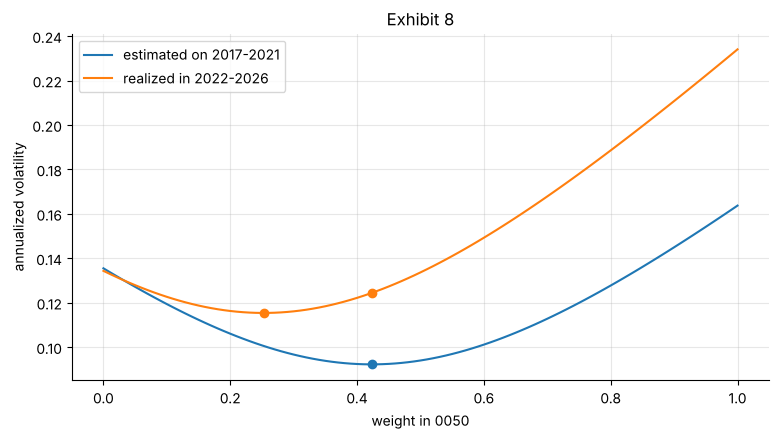

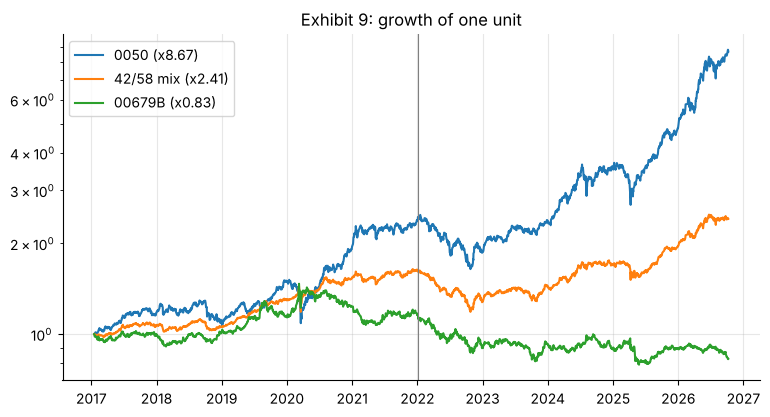

test-window CAGR: mix 8.75%, 0050 31.43%, 00679B -6.84%


In [15]:
ws = np.linspace(0, 1, 101)
vc = lambda e: np.sqrt(ws**2 * e["s1"]**2 + (1 - ws)**2 * e["s2"]**2 + 2 * ws * (1 - ws) * e["cov"])
fig, ax = plt.subplots()
ax.plot(ws, vc(e0), label="estimated on 2017-2021"); ax.plot(ws, vc(e1), label="realized in 2022-2026")
ax.plot([e0["w_mv"]], [e0["s_mv"]], "o", color="tab:blue"); ax.plot([e1["w_mv"]], [e1["s_mv"]], "o", color="tab:orange")
ax.plot([w_is], [realized], "o", color="tab:orange")
ax.set_xlabel("weight in 0050"); ax.set_ylabel("annualized volatility"); ax.set_title("Exhibit 8"); ax.legend(); plt.show()

W = lambda w: np.concatenate([[1.0], np.cumprod(1 + w * R1 + (1 - w) * R2)])
dts = [date.fromisoformat(BASE)] + ret["date"].to_list()
fig, ax = plt.subplots()
for w_, lab in ((1.0, "0050"), (w_is, "42/58 mix"), (0.0, "00679B")):
    ax.plot(dts, W(w_), label=f"{lab} (x{W(w_)[-1]:.2f})")
ax.set_yscale("log"); ax.axvline(date(2022, 1, 3), color="grey", lw=0.8); ax.set_title("Exhibit 9: growth of one unit"); ax.legend(); plt.show()
cg = lambda x: np.prod(1 + x) ** (A / len(x)) - 1
print(f"test-window CAGR: mix {cg(mix(w_is, OOS)):.2%}, 0050 {cg(mix(1, OOS)):.2%}, 00679B {cg(mix(0, OOS)):.2%}")

In [16]:
kelly = pl.DataFrame([{"window": k, "e1": v["e1"], "e2": v["e2"], "s1": v["s1"], "s2": v["s2"], "rho": v["rho"], "f1": v["f1"], "f2": v["f2"],
                       "L": v["lev"], "wT_0050": v["wT1"], "SR*": v["sr_star"]} for k, v in E.items()])
print(f"Example 8: det = {np.linalg.det(F['S']):.4e}; g* (model) = {RF + 0.5 * F['sr_star']**2:.2%}; exact g at f* = {g(fstar):.2%}")
kelly   # Exhibit 10 (in-sample; not recommendations)

Example 8: det = 7.2809e-04; g* (model) = 65.76%; exact g at f* = 63.74%


window,e1,e2,s1,s2,rho,f1,f2,L,wT_0050,SR*
str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""full""",0.227510,-0.025466,0.201060,0.134959,-0.105632,5.591150,-0.518292,5.072858,1.102170,1.133684
"""2017–2021""",0.172255,0.023196,0.163706,0.135475,-0.221314,7.001953,3.136410,10.138363,0.690639,1.130873
"""2022–2026""",0.285791,-0.076794,0.234031,0.134335,-0.021900,5.166981,-4.058375,1.108605,4.660794,1.337287


## Part 8 — KKT: equity floor and leverage cap (Exhibit 11)

In [17]:
# Example 9: minimum variance with w1 >= 0.6 (full sample)
Vw = lambda w: w * w * S[0, 0] + (1 - w)**2 * S[1, 1] + 2 * w * (1 - w) * S[0, 1]
dV = 2 * S @ np.array([0.6, 0.4]); nu = dV[0] - dV[1]
print(f"floor binds (w* = {F['w_mv']:.1%}); nu = {nu:.4f}; vol {math.sqrt(Vw(0.6)):.2%} vs unconstrained {F['s_mv']:.2%}; "
      f"floor at 59%: dV predicted {-0.01 * nu:.6f}, exact {Vw(0.59) - Vw(0.6):.6f}, vol {math.sqrt(Vw(0.59)):.2%}")

# Example 10: enumerate active sets for max g_model s.t. f1 + f2 <= 2, f >= 0
ev = np.array([F["e1"], F["e2"]]); cap = 2.0
rows = []
f_none = np.linalg.solve(S, ev); rows.append(("none", f_none, {}))
sol3 = np.linalg.solve(np.array([[S[0, 0], S[0, 1], 1], [S[1, 0], S[1, 1], 1], [1, 1, 0]]), [ev[0], ev[1], cap])
rows.append(("cap only", sol3[:2], {"nu_c": sol3[2]}))
for fixed, other in ((1, 0), (0, 1)):                     # cap with f2 = 0, cap with f1 = 0
    f = np.zeros(2); f[other] = cap; gr = ev - S @ f
    rows.append((f"cap and f{fixed + 1}>=0", f, {"nu_c": gr[other], f"nu_{fixed + 1}": gr[other] - gr[fixed]}))
f = np.array([ev[0] / S[0, 0], 0.0]); rows.append(("f2>=0 only", f, {"nu_2": -(ev - S @ f)[1]}))
pl.DataFrame([{"binding": n, "f1": f[0], "f2": f[1], "multipliers": ", ".join(f"{k} = {float(v):.3f}" for k, v in mlt.items()) or "—",
               "feasible": bool(f.sum() <= cap + 1e-9 and (f >= -1e-9).all()), "multipliers >= 0": (all(v >= 0 for v in mlt.values()) if mlt else None),
               "model growth": g_model(f)} for n, f, mlt in rows])

floor binds (w* = 32.7%); nu = 0.0351; vol 12.69% vs unconstrained 10.64%; floor at 59%: dV predicted -0.000351, exact -0.000344, vol 12.55%


binding,f1,f2,multipliers,feasible,multipliers >= 0,model growth
str,f64,f64,str,bool,bool,f64
"""none""",5.591150,-0.518292,"""—""",false,null,0.657619
"""cap only""",4.584862,-2.584862,"""nu_c = 0.035""",false,true,0.604219
"""cap and f2>=0""",2.000000,0.000000,"""nu_c = 0.147, nu_2 = 0.166""",true,true,0.389168
"""cap and f1>=0""",0.000000,2.000000,"""nu_c = -0.062, nu_1 = -0.295""",true,false,-0.072360
"""f2>=0 only""",5.627898,0.000000,"""nu_2 = 0.009""",false,true,0.655200


In [18]:
def kelly_capped(cap, fun=g):
    res = minimize(lambda f: -fun(f), x0=[0.5, 0.5], method="SLSQP", bounds=[(0, None), (0, None)],
                   constraints=[{"type": "ineq", "fun": lambda f: cap - f.sum()}])
    return res.x, -res.fun
for name, fun in (("model", g_model), ("exact", g)):
    x2, g2 = kelly_capped(2.0, fun)
    nu_c = (kelly_capped(2.01, fun)[1] - kelly_capped(1.99, fun)[1]) / 0.02
    print(f"{name:5s}: f = {x2.round(4)}, growth {g2:.4%}, shadow price of the cap {nu_c:.4f}")
print(f"model: raising the cap to 2.1 adds {(g_model((2.1, 0)) - g_model((2, 0))) * 100:.3f} pp")

model: f = [2. 0.], growth 38.9168%, shadow price of the cap 0.1467
exact: f = [2. 0.], growth 38.8741%, shadow price of the cap 0.1461
model: raising the cap to 2.1 adds 1.446 pp


## Part 9 — Numerical gradients, Newton's method and gradient ascent (Exhibit 12)

Newton path: [(0.0, 0.0), (5.5621, -0.5156), (5.3231, -0.2675), (5.3186, -0.2641), (5.3186, -0.2641)]  g* = 64.0296%
numerical gradient at the optimum: [ 0. -0.]
curvatures of Sigma [0.0179 0.0408], kappa 2.29, alpha 34.1, model factor 0.39
curvatures at the optimum [0.0198 0.0493]
iterations to 1e-6: GA 18, Newton 2;  to 1e-10: GA 30, Newton 3
worst day at the exact optimum: -53.69%


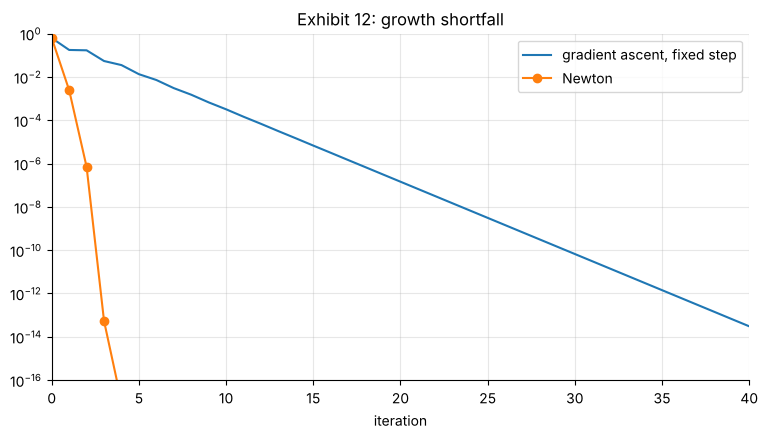

In [19]:
def num_grad(fun, x, h=1e-5):
    E_ = np.eye(len(x)); return np.array([(fun(x + h * E_[i]) - fun(x - h * E_[i])) / (2 * h) for i in range(len(x))])

f = np.zeros(2); nt = [f.copy()]
for k in range(5):
    gr, Hh = grad_hess(f); f = f - np.linalg.solve(Hh, gr); nt.append(f.copy())
fopt = nt[-1]; gopt = g(fopt)
print("Newton path:", [tuple(float(v) for v in p.round(4)) for p in nt[:5]], f" g* = {gopt:.4%}")
print("numerical gradient at the optimum:", num_grad(g, fopt).round(8))
eig = np.linalg.eigvalsh(F["S"]); alpha_ = 2 / eig.sum()
f = np.zeros(2); ga = [gopt - g(f)]
for k in range(60):
    f = f + alpha_ * grad_hess(f)[0]; ga.append(gopt - g(f))
nt_gap = [gopt - g(p) for p in nt]
first_below = lambda seq, tol: next(i for i, v in enumerate(seq) if v < tol)
print(f"curvatures of Sigma {eig.round(4)}, kappa {eig[1] / eig[0]:.2f}, alpha {alpha_:.1f}, model factor {(eig[1] - eig[0]) / eig.sum():.2f}")
print(f"curvatures at the optimum {np.linalg.eigvalsh(-grad_hess(fopt)[1]).round(4)}")
print(f"iterations to 1e-6: GA {first_below(ga, 1e-6)}, Newton {first_below(nt_gap, 1e-6)};  to 1e-10: GA {first_below(ga, 1e-10)}, Newton {first_below(nt_gap, 1e-10)}")
print(f"worst day at the exact optimum: {(r + X @ fopt).min():.2%}")
fig, ax = plt.subplots()
ax.semilogy(range(len(ga)), np.maximum(ga, 1e-17), label="gradient ascent, fixed step")
ax.semilogy(range(len(nt_gap)), np.maximum(nt_gap, 1e-17), "o-", label="Newton")
ax.set_xlim(0, 40); ax.set_ylim(1e-16, 1); ax.set_xlabel("iteration"); ax.set_title("Exhibit 12: growth shortfall"); ax.legend(); plt.show()

## Part 10 — Practice-problem solutions (computational)

In [20]:
def two(s1, s2, rho, e1=None, e2=None):
    c = rho * s1 * s2; D = s1**2 + s2**2 - 2 * c
    out = {"w*": (s2**2 - c) / D, "sigma_min": math.sqrt((s1**2 * s2**2 - c * c) / D)}
    if e1 is not None:
        det = s1**2 * s2**2 - c * c; f1, f2 = (s2**2 * e1 - c * e2) / det, (s1**2 * e2 - c * e1) / det
        sr1, sr2 = e1 / s1, e2 / s2
        out.update(f1=f1, f2=f2, L=f1 + f2, wT1=f1 / (f1 + f2), SR=math.sqrt((sr1**2 + sr2**2 - 2 * rho * sr1 * sr2) / (1 - rho**2)))
    return out

print("PP2 ", f"exact {0.95 * 1.03 - 1:.2%}, linear {-0.02:.2%}, cross {-0.05 * 0.03:.2%}, at 4%: {0.95 * 1.04 - 1:.2%}")
print("PP4 ", f"T2 {0.05 - 0.3**2 / 8:.4%}, exact {math.sqrt(1.2 * 0.9) - 1:.4%}")
print("PP6 ", [(p, p[0]**3 + p[1]**3 - 3 * p[0] - 12 * p[1] + 20, 36 * p[0] * p[1]) for p in ((1, 2), (-1, -2), (1, -2), (-1, 2))])
print("PP7 ", {k: round(v, 4) for k, v in two(0.30, 0.10, 0.0).items()})
print("PP9 ", {k: round(v, 4) for k, v in two(0.25, 0.15, 0.3).items()}, f"50/50 vol {math.sqrt(0.25 * 0.0625 + 0.25 * 0.0225 + 0.5 * 0.01125):.2%}")
print("PP11/12", {k: round(v, 4) for k, v in two(0.20, 0.08, 0.25, 0.06, 0.02).items()}, f"g* = {0.02 + 0.5 * two(0.20, 0.08, 0.25, 0.06, 0.02)['SR']**2:.2%}")
p13 = two(0.20, 0.40, 0.95); c13 = 0.95 * 0.2 * 0.4
print("PP13", {k: round(v, 4) for k, v in p13.items()}, f"nu at w=1: {2 * (c13 - 0.04):.4f}")
f1c = (0.10 - 0.04 + 0.01 * 2) / (0.04 + 0.01)
print("PP14", f"unconstrained (2.5, 4); capped ({f1c:.2f}, {2 - f1c:.2f}), nu_c = {0.10 - 0.04 * f1c:.3f}")

PP2  exact -2.15%, linear -2.00%, cross -0.15%, at 4%: -1.20%
PP4  T2 3.8750%, exact 3.9230%
PP6  [((1, 2), 2, 72), ((-1, -2), 38, 72), ((1, -2), 34, -72), ((-1, 2), 6, -72)]
PP7  {'w*': 0.1, 'sigma_min': 0.0949}
PP9  {'w*': 0.18, 'sigma_min': 0.1431} 50/50 vol 16.39%
PP11/12 {'w*': 0.0625, 'sigma_min': 0.0791, 'f1': 1.2667, 'f2': 2.3333, 'L': 3.6, 'wT1': 0.3519, 'SR': 0.3502} g* = 8.13%
PP13 {'w*': 1.75, 'sigma_min': 0.114} nu at w=1: 0.0720
PP14 unconstrained (2.5, 4); capped (1.60, 0.40), nu_c = 0.036


In [21]:
# PP16: walk-forward, each year's minimum-variance weight held through the following year
rows = []
for y in range(2018, 2027):
    w_prev = est(yr == y - 1)["w_mv"]; cur = yr == y
    rows.append({"year": y, "w_prev": w_prev, "vol_prev_w": vol(mix(w_prev, cur)), "vol_50_50": vol(mix(0.5, cur)),
                 "vol_best": est(cur)["s_mv"]})
wf = pl.DataFrame(rows).with_columns((pl.col("vol_prev_w") < pl.col("vol_50_50")).alias("beats_50_50"))
print("years beating 50/50:", wf["beats_50_50"].sum(), "of", wf.height,
      "| means:", {c: f"{wf[c].mean():.2%}" for c in ("vol_prev_w", "vol_50_50", "vol_best")})
wf

years beating 50/50: 6 of 9 | means: {'vol_prev_w': '10.84%', 'vol_50_50': '11.64%', 'vol_best': '10.07%'}


year,w_prev,vol_prev_w,vol_50_50,vol_best,beats_50_50
i64,f64,f64,f64,f64,bool
2018,0.452246,0.070731,0.076032,0.062702,true
2019,0.300055,0.077113,0.064960,0.064960,false
2020,0.501018,0.142532,0.142508,0.142175,false
2021,0.471090,0.096574,0.098573,0.093117,true
2022,0.361104,0.125088,0.130681,0.125086,true
2023,0.363781,0.103103,0.102886,0.102350,false
2024,0.437672,0.110632,0.122176,0.089943,true
2025,0.217908,0.134650,0.146433,0.133048,true
2026,0.289263,0.115020,0.163074,0.093159,true


### Extension: how long should the estimation window be?

Practice Problem 16 re-estimated the weight once a year from the previous calendar year. Generalize it. For estimation windows of 6, 12, 24 and 36 months, re-estimate the minimum-variance weight at the end of every month and hold it for the next month, computing returns daily. Compare the out-of-sample volatility of each rule with the 50/50 mix and with the full-sample weight (which uses future data). Then repeat with weekly instead of daily returns for estimation. Which window and which frequency would you have chosen, and how much of the gap to perfect foresight does each close? [[LM35]] returns to this question with shrinkage estimators.

In [22]:
# starter: month-end rebalancing dates and a helper for one estimation window
month_ends = ret.group_by_dynamic("date", every="1mo").agg(pl.col("date").last().alias("d"))["d"].to_list()
def min_var_weight(mask):
    return est(mask)["w_mv"]
# for i, d in enumerate(month_ends[12:-1], start=12): ...  (your code)